# Kezekshi: прогноз метрик сервера

## 1. Загрузка данных
Минутные метрики демо-магазина ShopSim из S3 (`shopsim/dataset`) и журнал событий `events.jsonl` с точным временем каждой проблемы и наплыва.

In [1]:
import os, glob, json, math, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import zipfile, os
zipfile.ZipFile('shopsim-data.zip').extractall('.')
print(os.listdir('shopsim-data'))

['dataset', 'events.jsonl']


In [3]:
df = pd.concat(pd.read_csv(f) for f in sorted(glob.glob('shopsim-data/dataset/metrics-*.csv')))
df['time'] = pd.to_datetime(df['time'], utc=True)
df = df.set_index('time').sort_index()
events = [json.loads(l) for l in open('shopsim-data/events.jsonl')]

print(df.shape)
print(df.index.min(), df.index.max())
print(df.index.to_series().diff().value_counts())

(9079, 45)
2026-11-17 09:39:00+00:00 2026-11-23 16:57:00+00:00
time
0 days 00:01:00    9078
Name: count, dtype: int64


## 2. Очистка: ручные поломки и режимы нагрузки
Ручные поломки сервера (`/break`) в метках записаны как `none`, поэтому они помечаются отдельно по логу демо-сервера с запасом 10 минут. Нагрузку на демо-сервер дважды увеличивали, отсюда три режима.

In [4]:
gaps = df.index.to_series().diff()
print(gaps.value_counts().head())

time
0 days 00:01:00    9078
Name: count, dtype: int64


In [5]:
# Ручные поломки сервера (/break), время в UTC, из лога demo-сервера.
# В метках они записаны как incident = 'none', поэтому помечаем их отдельно.
manual = [
    ('2026-11-22 17:31:00', '2026-11-22 17:36:00'),   # cpu, 300 с
    ('2026-11-23 14:21:11', '2026-11-23 14:26:11'),   # cpu, 300 с
    ('2026-11-23 14:51:42', '2026-11-23 14:54:42'),   # down, 180 с
    ('2026-11-23 15:03:58', '2026-11-23 15:06:58'),   # down, 180 с
    ('2026-11-23 15:50:56', '2026-11-23 15:55:56'),   # cpu, 300 с
    ('2026-11-23 17:57:57', '2026-11-23 18:00:57'),   # down, 180 с
]
PAD = pd.Timedelta('10min')   # запас до и после поломки

df['manual_break'] = False
for start, end in manual:
    a = pd.Timestamp(start, tz='UTC') - PAD
    b = pd.Timestamp(end, tz='UTC') + PAD
    df.loc[a:b, 'manual_break'] = True

print('помечено минут:', df['manual_break'].sum())

помечено минут: 111


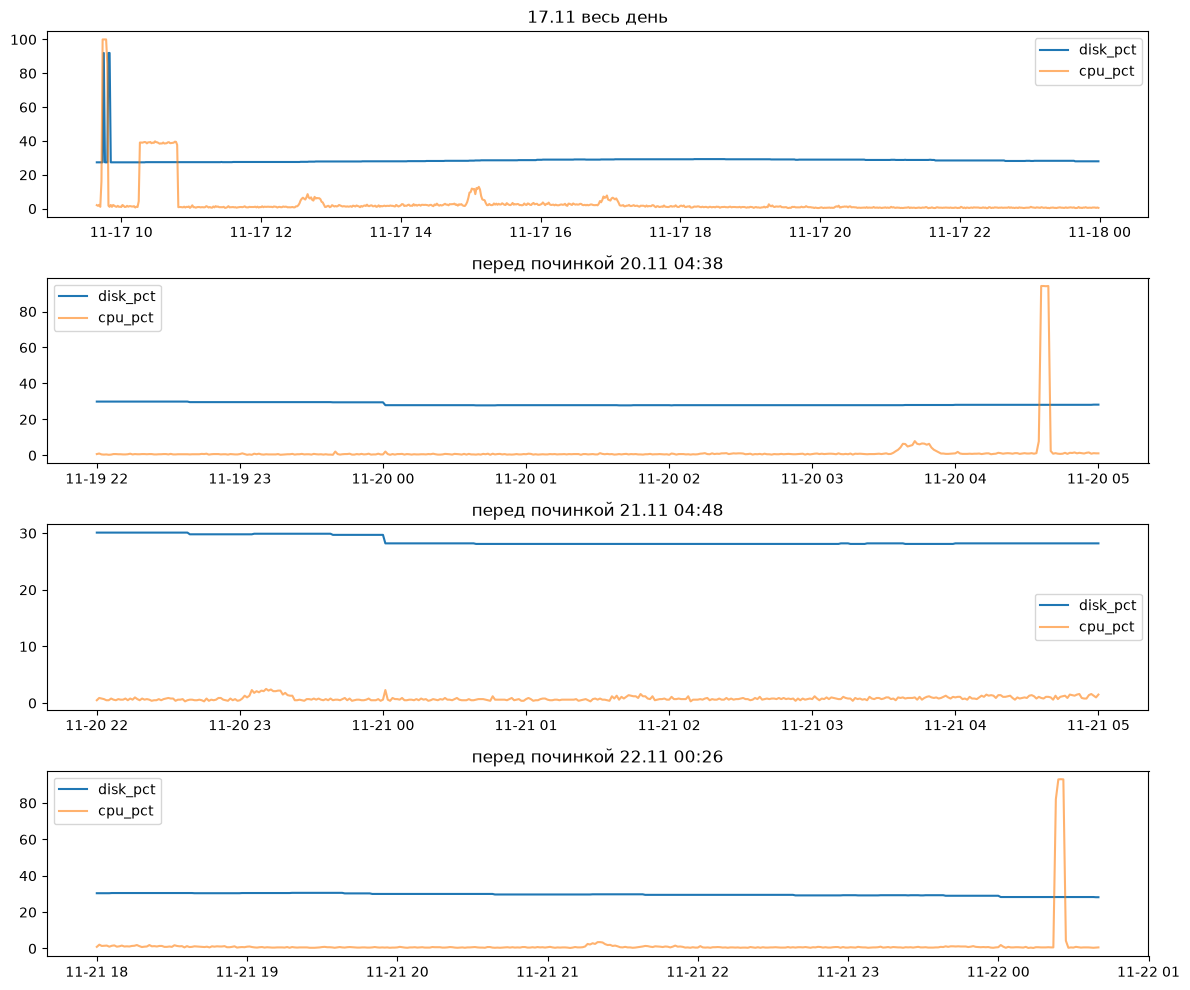

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10))
windows = [('2026-11-17 00:00', '2026-11-17 23:59', '17.11 весь день'),
           ('2026-11-19 22:00', '2026-11-20 05:00', 'перед починкой 20.11 04:38'),
           ('2026-11-20 22:00', '2026-11-21 05:00', 'перед починкой 21.11 04:48'),
           ('2026-11-21 18:00', '2026-11-22 00:40', 'перед починкой 22.11 00:26')]
for ax, (a, b, title) in zip(axes, windows):
    part = df.loc[a:b]
    ax.plot(part.index, part['disk_pct'], label='disk_pct')
    ax.plot(part.index, part['cpu_pct'], label='cpu_pct', alpha=0.6)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

In [7]:
b1 = pd.Timestamp('2026-11-22 14:45', tz='UTC')
b2 = pd.Timestamp('2026-11-23 14:35', tz='UTC')
df['regime'] = 1
df.loc[b1:, 'regime'] = 2
df.loc[b2:, 'regime'] = 3

local = df.index.tz_convert('Asia/Almaty')
df['hour'] = local.hour
df['weekday'] = local.weekday

print(df.groupby('regime')['rps'].agg(['mean', 'max', 'count']))

             mean     max  count
regime                          
1        2.556484  36.384   7506
2        6.816471  37.601   1430
3       24.816210  46.527    143


## 3. EDA
Анализ признаков, которые есть у агента Kezekshi на реальных серверах: распределения, суточный ритм, поведение во время проблем и наплывов. Минуты ручных поломок исключены.

In [8]:
AGENT = ['cpu_pct', 'mem_pct', 'disk_pct', 'status_5xx', 'debug_lines',
         'unauthorized', 'not_found', 'latency_p95_ms']
clean = df[~df['manual_break']]
clean[AGENT].describe().T

,count,mean,std,min,25%,50%,75%,max
cpu_pct,8968.0,2.889474,8.406998,0.3,0.8,1.3,2.2,100.0
mem_pct,8968.0,52.874331,2.797267,47.7,51.9,52.8,53.5,85.7
disk_pct,8968.0,29.454182,1.672793,27.4,28.4,29.4,30.1,92.0
status_5xx,8968.0,0.040254,0.681812,0.0,0.0,0.0,0.0,32.0
debug_lines,8968.0,68.708519,571.080310,0.0,0.0,0.0,0.0,10406.0
unauthorized,8968.0,0.635816,15.793500,0.0,0.0,0.0,0.0,527.0
not_found,8968.0,0.388158,8.034704,0.0,0.0,0.0,0.0,252.0
latency_p95_ms,8968.0,124.114886,13.140114,0.0,119.7,126.3,131.1,395.6


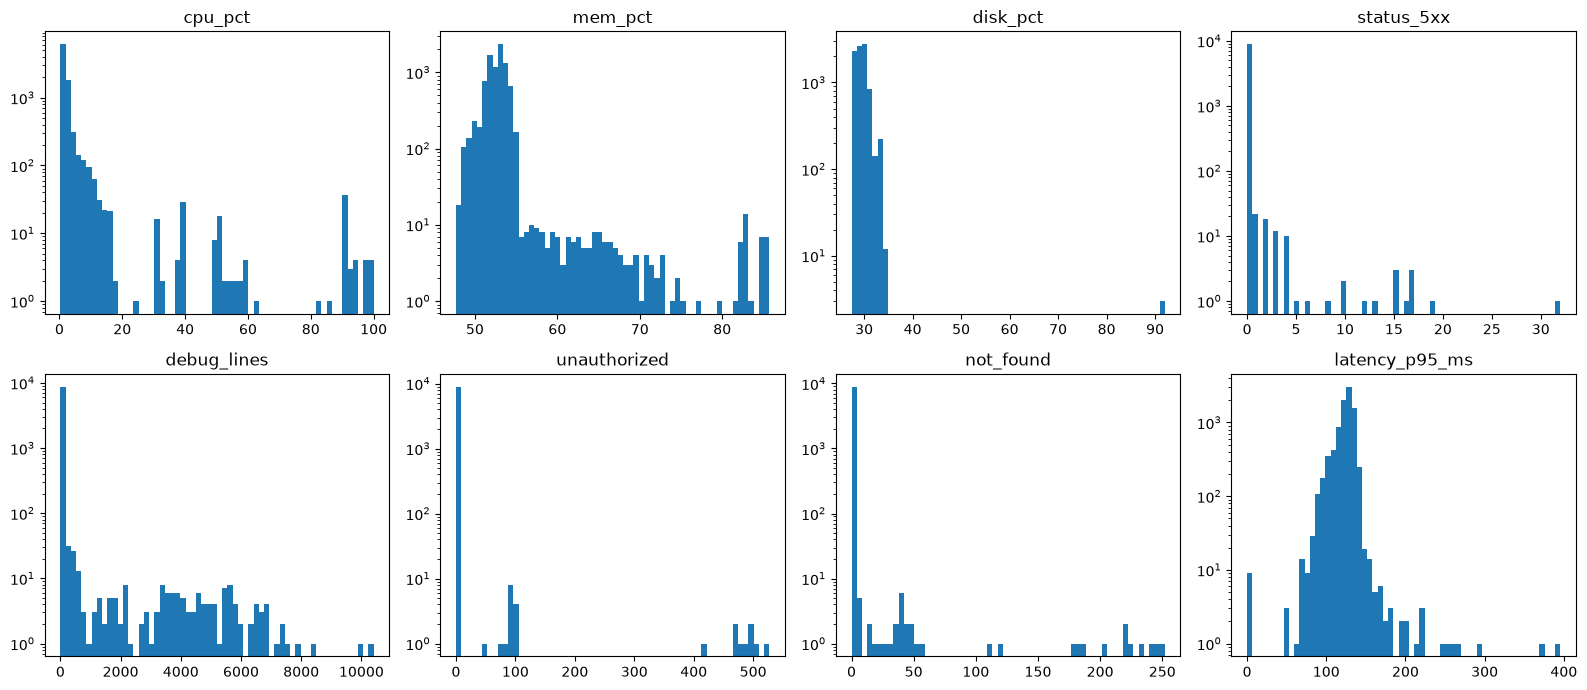

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, AGENT):
    ax.hist(clean[col], bins=60)
    ax.set_yscale('log')
    ax.set_title(col)
plt.tight_layout()
plt.show()

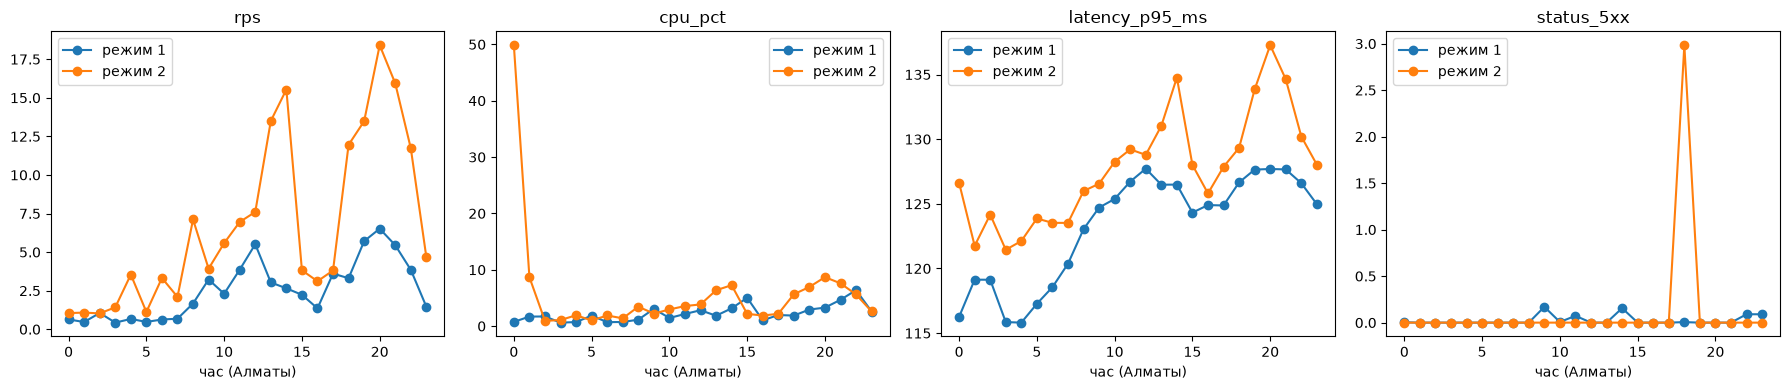

In [10]:
cols = ['rps', 'cpu_pct', 'latency_p95_ms', 'status_5xx']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cols):
    for r in (1, 2):
        part = clean[clean['regime'] == r]
        ax.plot(part.groupby('hour')[col].mean(), marker='o', label=f'режим {r}')
    ax.set_title(col)
    ax.set_xlabel('час (Алматы)')
    ax.legend()
plt.tight_layout()
plt.show()

In [11]:
print(df[df['disk_pct'] > 50][['disk_pct', 'incident', 'manual_break']])
print(df[df['latency_p95_ms'] == 0][['rps', 'incident', 'manual_break']])

                           disk_pct incident  manual_break
time                                                      
2026-11-17 09:45:00+00:00      92.0     none         False
2026-11-17 09:49:00+00:00      92.0     none         False
2026-11-17 09:50:00+00:00      92.0     none         False
                           rps        incident  manual_break
time                                                        
2026-11-18 19:08:00+00:00  0.0            none         False
2026-11-18 22:43:00+00:00  0.0  cleanup_broken         False
2026-11-19 22:25:00+00:00  0.0            none         False
2026-11-19 23:03:00+00:00  0.0            none         False
2026-11-19 23:17:00+00:00  0.0            none         False
2026-11-19 23:38:00+00:00  0.0            none         False
2026-11-20 22:33:00+00:00  0.0            none         False
2026-11-20 23:31:00+00:00  0.0            none         False
2026-11-22 00:49:00+00:00  0.0         cpu_hog         False


## 4. Feature engineering
Прогнозируются 4 метрики, которые predictor отправляет в модель: `cpu`, `mem`, `disk`, `errors`. Для GRU на вход идёт окно сырых значений. Для LightGBM то же окно разложено в признаки: лаги, скользящие среднее, std и максимум, изменения за 1 и 15 минут. Признаки времени есть только у LightGBM, в AWS их пока передать нельзя. Метки проблем в признаки не входят: на реальных серверах их нет.

In [12]:
FC = {'cpu': 'cpu_pct', 'mem': 'mem_pct', 'disk': 'disk_pct', 'errors': 'status_5xx'}
HORIZONS = [15, 30, 60]
WINDOW = 120

data = df[list(FC.values())].rename(columns={v: k for k, v in FC.items()}).astype(float)

In [13]:
feats = pd.DataFrame(index=data.index)
for f in FC:
    s = data[f]
    feats[f'{f}_now'] = s
    for l in (1, 5, 15, 30, 60):
        feats[f'{f}_lag{l}'] = s.shift(l)
    for w in (15, 60):
        r = s.rolling(w)
        feats[f'{f}_mean{w}'] = r.mean()
        feats[f'{f}_std{w}'] = r.std()
        feats[f'{f}_max{w}'] = r.max()
    feats[f'{f}_diff1'] = s.diff(1)
    feats[f'{f}_diff15'] = s.diff(15)

local = df.index.tz_convert('Asia/Almaty')
hour = local.hour + local.minute / 60
TIME = ['hour_sin', 'hour_cos', 'wd_sin', 'wd_cos']
feats['hour_sin'] = np.sin(2 * np.pi * hour / 24)
feats['hour_cos'] = np.cos(2 * np.pi * hour / 24)
feats['wd_sin'] = np.sin(2 * np.pi * local.weekday / 7)
feats['wd_cos'] = np.cos(2 * np.pi * local.weekday / 7)
feats['regime'] = df['regime']

print(feats.shape)

(9079, 61)


In [14]:
targets = pd.DataFrame(index=data.index)
for f in FC:
    for h in HORIZONS:
        targets[f'{f}_f{h}'] = data[f].shift(-h)

H = max(HORIZONS)
mb = df['manual_break'].astype(int)
past = mb.rolling(WINDOW + 1, min_periods=1).max()
future = mb.rolling(H + 1, min_periods=1).max().shift(-H).fillna(0)
enough = pd.Series(np.arange(len(df)) >= WINDOW, index=df.index)

valid = (past == 0) & (future == 0) & enough & targets.notna().all(axis=1) & feats.notna().all(axis=1)
print(valid.sum(), 'из', len(valid))

8527 из 9079


## 5. Разбиение по времени
Тест: последние 2 суток, валидация: сутки перед ними, обучение: всё раньше. Между частями зазор 60 минут, чтобы цели обучения не заглядывали в валидацию и тест. Нормализация (mean, std) считается только по обучающей части.

In [15]:
end = df.index.max()
test_start = end - pd.Timedelta('2D')
val_start = test_start - pd.Timedelta('1D')
gap = pd.Timedelta(minutes=H)
idx = df.index

train_mask = valid & (idx < val_start - gap)
val_mask = valid & (idx >= val_start) & (idx < test_start - gap)
test_mask = valid & (idx >= test_start)

for name, m in [('train', train_mask), ('val', val_mask), ('test', test_mask)]:
    print(name, m.sum(), idx[m].min(), idx[m].max(), df.loc[m, 'regime'].value_counts().to_dict())

train 4578 2026-11-17 11:39:00+00:00 2026-11-20 15:56:00+00:00 {1: 4578}
val 1380 2026-11-20 16:57:00+00:00 2026-11-21 15:56:00+00:00 {1: 1380}
test 2449 2026-11-21 16:57:00+00:00 2026-11-23 13:11:00+00:00 {1: 1308, 2: 1141}


In [16]:
norm_src = data[(idx < val_start) & ~df['manual_break']]
mean = norm_src.mean()
std = norm_src.std().replace(0, 1)
print(pd.DataFrame({'mean': mean, 'std': std}))

             mean       std
cpu      2.181505  6.281416
mem     52.167739  1.491134
disk    29.090479  1.861199
errors   0.010929  0.324020


## 6. Базовые модели
1. Naive: будет как сейчас.
2. Seasonal naive: будет как вчера в это же время.
3. Holt + сезонность: текущая модель в AWS (`src/lambda/predictor/model.py`), вызывается так же, как в predictor: последние 180 минут поминутно и 7 дней истории по 5 минут.

Все модели сравниваются на одних и тех же точках теста (каждые 5 минут). Метрики MAE и RMSE считаются по всему тесту и отдельно на минутах с проблемами и наплывами.

In [17]:
EVAL_STEP = 5
eval_idx = idx[test_mask][::EVAL_STEP]

event = ((df['incident'] != 'none') | (df['flash_multiplier'] > 1)).astype(int)
event_soon = event.rolling(H + 1, min_periods=1).max().shift(-H).fillna(0)
is_event = (event | event_soon.astype(int)).astype(bool)

def score(pred, name):
    rows = []
    for part, pts in [('all', pred.index), ('events', pred.index[is_event[pred.index]])]:
        for f in FC:
            for h in HORIZONS:
                c = f'{f}_f{h}'
                e = pred.loc[pts, c] - targets.loc[pts, c]
                rows.append({'model': name, 'part': part, 'metric': f, 'h': h,
                             'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean())})
    return pd.DataFrame(rows)

print(len(eval_idx), is_event[eval_idx].sum())

490 294


In [18]:
naive = pd.DataFrame({f'{f}_f{h}': data.loc[eval_idx, f] for f in FC for h in HORIZONS}, index=eval_idx)
snaive = pd.DataFrame({f'{f}_f{h}': data[f].shift(1440 - h).loc[eval_idx] for f in FC for h in HORIZONS}, index=eval_idx)

results = pd.concat([score(naive, 'naive'), score(snaive, 'seasonal_naive')])

In [19]:
import sys, importlib
p = os.path.abspath(os.path.join('ai-oncall-engineer-main', 'src', 'lambda', 'predictor'))
sys.path.insert(0, p)
importlib.invalidate_caches()
import model as holt_model
def to_sec(index):
    return np.asarray((index - pd.Timestamp('1970-01-01', tz='UTC')) // pd.Timedelta('1s'), dtype=float)

agg = {'cpu': 'mean', 'mem': 'mean', 'disk': 'max', 'errors': 'sum'}
hist5 = pd.DataFrame({f: data[f].resample('5min').agg(a) for f, a in agg.items()})
sec = to_sec(data.index)
sec5 = to_sec(hist5.index)

def holt_predict(t):
    i = data.index.get_loc(t)
    m = (hist5.index > t - pd.Timedelta('7D')) & (hist5.index <= t - pd.Timedelta('5min'))
    series = {}
    for f in FC:
        series[f] = {'recent': list(zip(sec[i - 179:i + 1], data[f].values[i - 179:i + 1])),
                     'history': list(zip(sec5[m], hist5[f].values[m]))}
    out = holt_model.forecast(series, sec[i])
    return {f'{f}_f{h}': out[f][f'f{h}'] for f in FC for h in HORIZONS}

holt = pd.DataFrame([holt_predict(t) for t in eval_idx], index=eval_idx)
results = pd.concat([results, score(holt, 'holt_seasonal')])

In [20]:
def table(part, stat='MAE'):
    return results[results['part'] == part].pivot_table(index='model', columns=['metric', 'h'], values=stat).round(2)

display(table('all'))
display(table('events'))

metric           cpu              disk             errors               mem  \
h                 15    30    60    15    30    60     15    30    60    15   
model                                                                         
holt_seasonal   2.10  2.67  2.74  0.12  0.20  0.26   0.05  0.07  0.16  0.98   
naive           1.93  2.50  2.61  0.11  0.20  0.33   0.05  0.07  0.16  0.84   
seasonal_naive  1.90  1.47  2.07  0.81  0.81  0.81   0.06  0.06  0.15  2.06   

metric                      
h                 30    60  
model                       
holt_seasonal   1.81  2.76  
naive           1.42  1.93  
seasonal_naive  2.06  2.11

metric           cpu              disk             errors               mem  \
h                 15    30    60    15    30    60     15    30    60    15   
model                                                                         
holt_seasonal   3.23  4.16  4.16  0.12  0.20  0.27   0.08  0.11  0.26  1.32   
naive           2.94  3.88  3.92  0.11  0.20  0.36   0.08  0.11  0.26  1.24   
seasonal_naive  2.72  1.71  2.51  0.74  0.75  0.75   0.07  0.07  0.22  2.55   

metric                      
h                 30    60  
model                       
holt_seasonal   2.46  3.64  
naive           2.11  2.80  
seasonal_naive  2.54  2.60

## 7. LightGBM
Отдельная модель на каждую метрику и горизонт (4 × 3 = 12 моделей). Цель: изменение метрики относительно текущего значения, итоговый прогноз = текущее значение + предсказанное изменение. Функция потерь L1, чтобы оптимизировать ту же MAE, по которой идёт сравнение. Ранняя остановка по валидации. Две версии: со всеми признаками и без признаков времени (как у GRU в AWS), чтобы сравнение с GRU было честным.

In [21]:
import lightgbm as lgb

FEATS_ALL = list(feats.columns)
FEATS_NO_TIME = [c for c in FEATS_ALL if c not in TIME]
LIMIT = {'cpu': 100, 'mem': 100, 'disk': 100, 'errors': None}

params = dict(objective='l1', learning_rate=0.05, num_leaves=31, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              n_estimators=2000, verbose=-1)

def train_lgbm(cols):
    preds, models = {}, {}
    for f in FC:
        for h in HORIZONS:
            c = f'{f}_f{h}'
            y = targets[c] - data[f]
            m = lgb.LGBMRegressor(**params)
            m.fit(feats.loc[train_mask, cols], y[train_mask],
                  eval_set=[(feats.loc[val_mask, cols], y[val_mask])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
            p = data.loc[eval_idx, f] + m.predict(feats.loc[eval_idx, cols])
            preds[c] = p.clip(0, LIMIT[f])
            models[c] = m
            print(c, 'деревьев:', m.best_iteration_)
    return pd.DataFrame(preds, index=eval_idx), models

lgbm, lgbm_models = train_lgbm(FEATS_ALL)
lgbm_nt, _ = train_lgbm(FEATS_NO_TIME)

cpu_f15 деревьев: 87


cpu_f30 деревьев: 76


cpu_f60 деревьев: 147


mem_f15 деревьев: 18


mem_f30 деревьев: 30


mem_f60 деревьев: 19


... (10 outputs left out)

disk_f15 деревьев: 37


disk_f30 деревьев: 46


disk_f60 деревьев: 19
errors_f15 деревьев: 1


errors_f30 деревьев: 1
errors_f60 деревьев: 1


In [22]:
results = results[~results['model'].isin(['lgbm', 'lgbm_no_time'])]
results = pd.concat([results, score(lgbm, 'lgbm'), score(lgbm_nt, 'lgbm_no_time')])
display(table('all'))
display(table('events'))

metric           cpu              disk             errors               mem  \
h                 15    30    60    15    30    60     15    30    60    15   
model                                                                         
holt_seasonal   2.10  2.67  2.74  0.12  0.20  0.26   0.05  0.07  0.16  0.98   
lgbm            1.81  2.30  2.37  0.11  0.18  0.29   0.05  0.07  0.16  0.85   
lgbm_no_time    1.78  2.30  2.45  0.11  0.18  0.28   0.05  0.07  0.16  0.85   
naive           1.93  2.50  2.61  0.11  0.20  0.33   0.05  0.07  0.16  0.84   
seasonal_naive  1.90  1.47  2.07  0.81  0.81  0.81   0.06  0.06  0.15  2.06   

metric                      
h                 30    60  
model                       
holt_seasonal   1.81  2.76  
lgbm            1.41  1.97  
lgbm_no_time    1.42  1.92  
naive           1.42  1.93  
seasonal_naive  2.06  2.11

metric           cpu              disk             errors               mem  \
h                 15    30    60    15    30    60     15    30    60    15   
model                                                                         
holt_seasonal   3.23  4.16  4.16  0.12  0.20  0.27   0.08  0.11  0.26  1.32   
lgbm            2.75  3.54  3.51  0.10  0.17  0.32   0.08  0.11  0.26  1.25   
lgbm_no_time    2.71  3.55  3.63  0.10  0.17  0.30   0.08  0.11  0.26  1.25   
naive           2.94  3.88  3.92  0.11  0.20  0.36   0.08  0.11  0.26  1.24   
seasonal_naive  2.72  1.71  2.51  0.74  0.75  0.75   0.07  0.07  0.22  2.55   

metric                      
h                 30    60  
model                       
holt_seasonal   2.46  3.64  
lgbm            2.12  2.83  
lgbm_no_time    2.12  2.79  
naive           2.11  2.80  
seasonal_naive  2.54  2.60

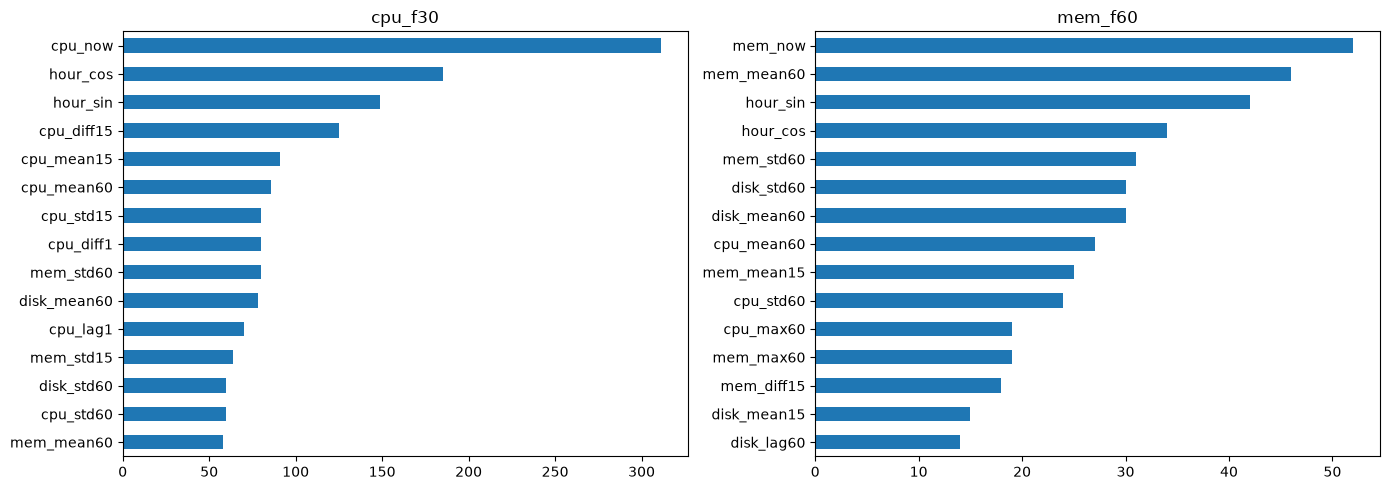

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, ['cpu_f30', 'mem_f60']):
    imp = pd.Series(lgbm_models[c].feature_importances_, index=FEATS_ALL).sort_values().tail(15)
    imp.plot.barh(ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

### Выводы по LightGBM
1. LightGBM обгоняет текущую модель в AWS (Holt + сезонность) по CPU и памяти на всех горизонтах. По CPU MAE ниже на 12–14% (на 60 минутах 2.37 против 2.74), по памяти на 22–29% на 30 и 60 минутах (на 60 минутах 1.97 против 2.76).
2. Относительно простого прогноза «как сейчас» выигрыш есть только по CPU: на 6–9% на всём тесте и на моментах с проблемами. По памяти LightGBM на уровне «как сейчас»: в обучающих данных мало утечек памяти, и все они при слабой нагрузке.
3. По CPU на 30 и 60 минут лучший результат у «как вчера в это же время» (1.47 и 2.07). Значит, в нагрузке на процессор есть всплески, которые повторяются каждый день в одно и то же время. В признаках LightGBM нет значения «вчера в момент прогноза», поэтому он их не ловит.
4. Диск и ошибки почти не меняются: все модели показывают одинаковую ошибку, учить там нечего.
5. Признаки времени почти не влияют на качество (`lgbm` и `lgbm_no_time` почти равны). Значит, GRU в AWS без признаков времени теряет немного.
6. Ограничение: обучение пока только на режиме слабой нагрузки, тест в основном на сильной. Итоговые цифры нужно пересчитать, когда накопится 2 недели данных режима 3.

## 8. GRU
Вход: окно последних 120 минут по 4 метрикам, нормализованное mean и std обучающей части. Выход: значения метрик через 15, 30 и 60 минут в той же нормализации. Сеть прогнозирует изменение, которое прибавляется к последнему значению окна (residual), по той же причине, что и у LightGBM. Два слоя GRU по 64 нейрона, функция потерь L1, Adam, ранняя остановка по валидации.

In [24]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

F = len(FC)
Xn = ((data - mean) / std).to_numpy(dtype=np.float32)
pos_train = np.where(train_mask)[0]
pos_val = np.where(val_mask)[0]
pos_eval = idx.get_indexer(eval_idx)

class Windows(Dataset):
    def __init__(self, pos):
        self.pos = pos
    def __len__(self):
        return len(self.pos)
    def __getitem__(self, i):
        p = self.pos[i]
        x = Xn[p - WINDOW + 1:p + 1]
        y = Xn[[p + h for h in HORIZONS]]
        return torch.from_numpy(x.copy()), torch.from_numpy(y)

class GRUForecast(nn.Module):
    def __init__(self, f, horizons, hidden=64, layers=2):
        super().__init__()
        self.h, self.f = horizons, f
        self.gru = nn.GRU(f, hidden, num_layers=layers, batch_first=True, dropout=0.1)
        self.head = nn.Linear(hidden, horizons * f)
    def forward(self, x):
        out, _ = self.gru(x)
        d = self.head(out[:, -1]).reshape(-1, self.h, self.f)
        return x[:, -1:, :] + d

print(len(pos_train), len(pos_val), len(pos_eval))

4578 1380 490


0 0.164 0.3035
1 0.1567 0.301
2 0.1543 0.3004
3 0.1518 0.2966
4 0.1475 0.2929
5 0.1445 0.2907
6 0.1427 0.2904
7 0.1412 0.2909
8 0.1398 0.2864
9 0.1381 0.2813
10 0.1368 0.2849
11 0.1354 0.2827
12 0.134 0.2811
13 0.1327 0.2802
14 0.1321 0.2802
15 0.1313 0.2786
16 0.129 0.2917
17 0.1284 0.2937
18 0.1273 0.2924
19 0.1258 0.2969
20 0.1258 0.3034


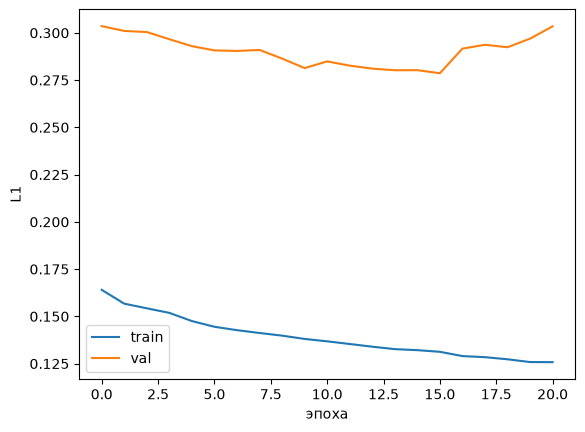

In [25]:
train_dl = DataLoader(Windows(pos_train), batch_size=128, shuffle=True)
val_dl = DataLoader(Windows(pos_val), batch_size=256)

gru = GRUForecast(F, len(HORIZONS))
opt = torch.optim.Adam(gru.parameters(), lr=1e-3)
loss_fn = nn.L1Loss()

best, best_state, wait, PATIENCE = float('inf'), None, 0, 5
history = []
for epoch in range(50):
    gru.train()
    tr = 0.0
    for x, y in train_dl:
        opt.zero_grad()
        loss = loss_fn(gru(x), y)
        loss.backward()
        opt.step()
        tr += loss.item() * len(x)
    tr /= len(pos_train)
    gru.eval()
    with torch.no_grad():
        va = sum(loss_fn(gru(x), y).item() * len(x) for x, y in val_dl) / len(pos_val)
    history.append((tr, va))
    print(epoch, round(tr, 4), round(va, 4))
    if va < best:
        best, best_state, wait = va, {k: v.clone() for k, v in gru.state_dict().items()}, 0
    else:
        wait += 1
        if wait >= PATIENCE:
            break
gru.load_state_dict(best_state)

plt.plot([h[0] for h in history], label='train')
plt.plot([h[1] for h in history], label='val')
plt.xlabel('эпоха')
plt.ylabel('L1')
plt.legend()
plt.show()

In [26]:
gru.eval()
with torch.no_grad():
    xb = torch.from_numpy(np.stack([Xn[p - WINDOW + 1:p + 1] for p in pos_eval]))
    yn = gru(xb).numpy()
y = yn * std.to_numpy(dtype=np.float32) + mean.to_numpy(dtype=np.float32)
gru_pred = pd.DataFrame({f'{f}_f{h}': np.clip(y[:, i, j], 0, LIMIT[f])
                         for j, f in enumerate(FC) for i, h in enumerate(HORIZONS)}, index=eval_idx)

results = results[results['model'] != 'gru']
results = pd.concat([results, score(gru_pred, 'gru')])
display(table('all'))
display(table('events'))

metric           cpu              disk             errors               mem  \
h                 15    30    60    15    30    60     15    30    60    15   
model                                                                         
gru             1.57  1.62  1.72  0.11  0.17  0.22   0.05  0.07  0.16  0.89   
holt_seasonal   2.10  2.67  2.74  0.12  0.20  0.26   0.05  0.07  0.16  0.98   
lgbm            1.81  2.30  2.37  0.11  0.18  0.29   0.05  0.07  0.16  0.85   
lgbm_no_time    1.78  2.30  2.45  0.11  0.18  0.28   0.05  0.07  0.16  0.85   
naive           1.93  2.50  2.61  0.11  0.20  0.33   0.05  0.07  0.16  0.84   
seasonal_naive  1.90  1.47  2.07  0.81  0.81  0.81   0.06  0.06  0.15  2.06   

metric                      
h                 30    60  
model                       
gru             1.36  1.71  
holt_seasonal   1.81  2.76  
lgbm            1.41  1.97  
lgbm_no_time    1.42  1.92  
naive           1.42  1.93  
seasonal_naive  2.06  2.11

metric           cpu              disk             errors               mem  \
h                 15    30    60    15    30    60     15    30    60    15   
model                                                                         
gru             2.35  2.39  2.45  0.10  0.17  0.25   0.08  0.11  0.26  1.30   
holt_seasonal   3.23  4.16  4.16  0.12  0.20  0.27   0.08  0.11  0.26  1.32   
lgbm            2.75  3.54  3.51  0.10  0.17  0.32   0.08  0.11  0.26  1.25   
lgbm_no_time    2.71  3.55  3.63  0.10  0.17  0.30   0.08  0.11  0.26  1.25   
naive           2.94  3.88  3.92  0.11  0.20  0.36   0.08  0.11  0.26  1.24   
seasonal_naive  2.72  1.71  2.51  0.74  0.75  0.75   0.07  0.07  0.22  2.55   

metric                      
h                 30    60  
model                       
gru             1.96  2.37  
holt_seasonal   2.46  3.64  
lgbm            2.12  2.83  
lgbm_no_time    2.12  2.79  
naive           2.11  2.80  
seasonal_naive  2.54  2.60

## 9. Сравнение моделей
Насколько каждая модель лучше «как сейчас» и текущей модели в AWS (Holt + сезонность), в процентах снижения MAE. Положительное число означает, что модель лучше.

In [27]:
def gain(part, ref):
    t = table(part)
    return ((1 - t / t.loc[ref]) * 100).round(1)

display(gain('all', 'naive'))
display(gain('events', 'naive'))
display(gain('all', 'holt_seasonal'))
display(gain('events', 'holt_seasonal'))

metric           cpu               disk               errors             \
h                 15    30    60     15     30     60     15    30   60   
model                                                                     
gru             18.7  35.2  34.1    0.0   15.0   33.3    0.0   0.0  0.0   
holt_seasonal   -8.8  -6.8  -5.0   -9.1    0.0   21.2    0.0   0.0  0.0   
lgbm             6.2   8.0   9.2    0.0   10.0   12.1    0.0   0.0  0.0   
lgbm_no_time     7.8   8.0   6.1    0.0   10.0   15.2    0.0   0.0  0.0   
naive            0.0   0.0   0.0    0.0    0.0    0.0    0.0   0.0  0.0   
seasonal_naive   1.6  41.2  20.7 -636.4 -305.0 -145.5  -20.0  14.3  6.2   

metric            mem              
h                  15    30    60  
model                              
gru              -6.0   4.2  11.4  
holt_seasonal   -16.7 -27.5 -43.0  
lgbm             -1.2   0.7  -2.1  
lgbm_no_time     -1.2   0.0   0.5  
naive             0.0   0.0   0.0  
seasonal_naive -145.2 -45.1  -9.3

metric           cpu               disk               errors              \
h                 15    30    60     15     30     60     15    30    60   
model                                                                      
gru             20.1  38.4  37.5    9.1   15.0   30.6    0.0   0.0   0.0   
holt_seasonal   -9.9  -7.2  -6.1   -9.1    0.0   25.0    0.0   0.0   0.0   
lgbm             6.5   8.8  10.5    9.1   15.0   11.1    0.0   0.0   0.0   
lgbm_no_time     7.8   8.5   7.4    9.1   15.0   16.7    0.0   0.0   0.0   
naive            0.0   0.0   0.0    0.0    0.0    0.0    0.0   0.0   0.0   
seasonal_naive   7.5  55.9  36.0 -572.7 -275.0 -108.3   12.5  36.4  15.4   

metric            mem              
h                  15    30    60  
model                              
gru              -4.8   7.1  15.4  
holt_seasonal    -6.5 -16.6 -30.0  
lgbm             -0.8  -0.5  -1.1  
lgbm_no_time     -0.8  -0.5   0.4  
naive             0.0   0.0   0.0  
seasonal_naive -105.6 -20.4   7.1

metric           cpu               disk               errors             \
h                 15    30    60     15     30     60     15    30   60   
model                                                                     
gru             25.2  39.3  37.2    8.3   15.0   15.4    0.0   0.0  0.0   
holt_seasonal    0.0   0.0   0.0    0.0    0.0    0.0    0.0   0.0  0.0   
lgbm            13.8  13.9  13.5    8.3   10.0  -11.5    0.0   0.0  0.0   
lgbm_no_time    15.2  13.9  10.6    8.3   10.0   -7.7    0.0   0.0  0.0   
naive            8.1   6.4   4.7    8.3    0.0  -26.9    0.0   0.0  0.0   
seasonal_naive   9.5  44.9  24.5 -575.0 -305.0 -211.5  -20.0  14.3  6.2   

metric            mem              
h                  15    30    60  
model                              
gru               9.2  24.9  38.0  
holt_seasonal     0.0   0.0   0.0  
lgbm             13.3  22.1  28.6  
lgbm_no_time     13.3  21.5  30.4  
naive            14.3  21.5  30.1  
seasonal_naive -110.2 -13.8  23.6

metric           cpu               disk               errors              \
h                 15    30    60     15     30     60     15    30    60   
model                                                                      
gru             27.2  42.5  41.1   16.7   15.0    7.4    0.0   0.0   0.0   
holt_seasonal    0.0   0.0   0.0    0.0    0.0    0.0    0.0   0.0   0.0   
lgbm            14.9  14.9  15.6   16.7   15.0  -18.5    0.0   0.0   0.0   
lgbm_no_time    16.1  14.7  12.7   16.7   15.0  -11.1    0.0   0.0   0.0   
naive            9.0   6.7   5.8    8.3    0.0  -33.3    0.0   0.0   0.0   
seasonal_naive  15.8  58.9  39.7 -516.7 -275.0 -177.8   12.5  36.4  15.4   

metric           mem              
h                 15    30    60  
model                             
gru              1.5  20.3  34.9  
holt_seasonal    0.0   0.0   0.0  
lgbm             5.3  13.8  22.3  
lgbm_no_time     5.3  13.8  23.4  
naive            6.1  14.2  23.1  
seasonal_naive -93.2  -3.3  28.6

## 10. Экспорт в ONNX
Модель сохраняется в формате, который ждёт Lambda `kezekshi-ml` (`src/ml/README.md`): вход `x` формы `[1, 120, 4]`, выход `[1, 3, 4]`, рядом `forecast.json` с признаками, горизонтами, mean и std. Проверка: ответ ONNX совпадает с PyTorch, и `src/ml/handler.py` (тот же код, что в AWS) выдаёт тот же прогноз.

In [28]:
torch.save(gru.state_dict(), 'gru_v1.pt')
results.to_csv('results_v1.csv', index=False)

In [29]:
import onnx
import onnxruntime as ort

os.makedirs('export', exist_ok=True)
gru.eval()
dummy = torch.zeros(1, WINDOW, F)
try:
    torch.onnx.export(gru, dummy, 'export/forecast.onnx', input_names=['x'], output_names=['y'],
                      opset_version=17, dynamo=False)
except Exception as e:
    print('старый экспорт не сработал:', e)
    torch.onnx.export(gru, (dummy,), 'export/forecast.onnx', input_names=['x'], output_names=['y'], dynamo=True)
onnx.checker.check_model(onnx.load('export/forecast.onnx'))

meta = {'version': 'gru-v1', 'window': WINDOW, 'features': list(FC), 'horizons': HORIZONS,
        'mean': [float(mean[f]) for f in FC], 'std': [float(std[f]) for f in FC]}
with open('export/forecast.json', 'w') as fh:
    json.dump(meta, fh, indent=2)
print(os.listdir('export'))

['forecast.json', 'forecast.onnx']


In [30]:
sess = ort.InferenceSession('export/forecast.onnx', providers=['CPUExecutionProvider'])
x1 = xb[:5].numpy()
onnx_out = np.concatenate([sess.run(None, {sess.get_inputs()[0].name: x1[k:k + 1]})[0] for k in range(5)])
print('макс. расхождение:', np.abs(onnx_out - yn[:5]).max())

макс. расхождение: 4.7683716e-07


In [31]:
import importlib
sys.path.insert(0, os.path.abspath(os.path.join('ai-oncall-engineer-main', 'src', 'ml')))
os.environ['MODEL_DIR'] = os.path.abspath('export')
importlib.invalidate_caches()
import handler

print(handler.handler({'task': 'info'}))
t = eval_idx[100]
i = idx.get_loc(t)
series = {f: [[float(sec[k]), float(data[f].iloc[k])] for k in range(i - 239, i + 1)] for f in FC}
print(handler.handler({'task': 'forecast', 'series': series}))
print(gru_pred.loc[t].round(2))

{'available': True, 'models': {'forecast': 'gru-v1', 'cause': None, 'anomaly': None}}
{'available': True, 'version': 'gru-v1', 'forecast': {'cpu': {'f15': 0.63, 'f30': 0.73, 'f60': 0.72}, 'mem': {'f15': 53.53, 'f30': 53.44, 'f60': 53.3}, 'disk': {'f15': 28.2, 'f30': 28.22, 'f60': 28.24}, 'errors': {'f15': 0.0, 'f30': 0.0, 'f60': 0.0}}}
cpu_f15        0.630000
cpu_f30        0.730000
cpu_f60        0.720000
mem_f15       53.529999
mem_f30       53.439999
mem_f60       53.299999
disk_f15      28.200001
disk_f30      28.219999
disk_f60      28.240000
errors_f15     0.000000
errors_f30     0.000000
errors_f60     0.000000
Name: 2026-11-22 01:17:00+00:00, dtype: float32
